<a href="https://colab.research.google.com/github/SungJiinwoo/Inteligencia_Artificial_Linguagens_Formais_e_Automatos/blob/main/Unidade5_SistemasEspecialistas/Triagem_Curadoria_TCC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Triagem das filas do Repositório de TCCs
## Sistema especialista com aprendizado supervisionado aplicado ao projeto do squad 5

**Inteligência Artificial e LFA | Sistemas Especialistas | Aula 13**
Profa. Kadidja Valéria · Engenharia de Software · UDF

**Grupo:** João Gabriel Pereira de Araújo e Julyane Ataides (squad 5)

No squad 5 estamos desenvolvendo o repositório público de TCCs dos cursos de TI da UDF. Para um TCC ser publicado, ele passa por duas filas de análise, e cada um de nós implementou uma delas no projeto:

| Etapa no sistema | Quem analisa | Itens do backlog | Responsável no squad |
|---|---|---|---|
| **Fila de cadastros**: a pessoa se cadastra, fica "não validada" e o administrador valida (com perfis) ou recusa | administrador | BL-11 Cadastro, BL-12 Validar ou recusar cadastro, BL-20 Gerenciar perfis | Julyane |
| **Fila da curadoria**: o orientador ou a coordenação envia o TCC, ele fica "pendente de análise" e a curadoria aprova ou rejeita | curadoria | BL-35 Fila de pendentes, BL-36 Analisar TCC | João |

As duas filas dependem uma da outra: só entra na fila da curadoria quem teve o cadastro **validado** pelo administrador e recebeu o perfil **Curadoria** (RN-03, RN-26, RN-27). Por isso fizemos um único sistema especialista com as duas partes:

* dois **modelos supervisionados**, um para cada fila, que preveem a decisão mais provável;
* a previsão de cada modelo vira um **fato**;
* uma **base de conhecimento única**, com regras das duas filas, e um **motor de inferência** que escolhe a regra e explica a recomendação.

As decisões continuam sendo humanas: quem valida cadastro é o administrador e quem aprova TCC é a curadoria. O sistema só recomenda e explica.

## 0. Estudo inicial (leitura do guia da IBM)

**O que é aprendizado de máquina?**
É a parte da IA em que o algoritmo aprende padrões a partir de dados de treino e depois usa esses padrões para fazer previsões sobre dados novos, sem que alguém escreva as regras na mão.

**O que caracteriza o aprendizado supervisionado?**
Os exemplos de treino já vêm com a resposta certa, que o guia chama de verdade fundamental (dados rotulados). É como estudar com o gabarito do lado: o modelo compara o que previu com a resposta e ajusta seus parâmetros.

**O que são atributos e rótulos?**
Atributos são as entradas que descrevem cada caso. Aqui são contagens tiradas do cadastro (palavras do nome, números no e-mail) e da versão do TCC (palavras do resumo, palavras-chave, tecnologias). O rótulo é a resposta conhecida: a decisão do administrador ou da curadoria.

**Como classificação difere de regressão?**
A classificação prevê uma categoria, como `validado`/`recusado` ou `aprovada`/`rejeitada`. A regressão prevê um número contínuo, como quantos dias um item fica na fila.

**Por que separar treino e teste?**
Para medir o modelo com casos que ele nunca viu. Avaliar com os mesmos dados do treino seria como fazer a prova com as questões da lista: dá para acertar tudo sem ter aprendido, e o overfitting passaria despercebido.

## 1. Preparar o ambiente
No Colab as bibliotecas já vêm instaladas. Se aparecer `ModuleNotFoundError`, rodar `%pip install pandas scikit-learn matplotlib` numa célula nova.

In [1]:
# bibliotecas que vamos usar
import pandas as pd                      # tabelas com os dados
import matplotlib.pyplot as plt          # gráficos
from datetime import date                # para comparar a data de apresentação com hoje
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

print("Bibliotecas carregadas.")

Bibliotecas carregadas.


## 2. Problema escolhido

| Item | Fila de cadastros (Julyane) | Fila da curadoria (João) |
|---|---|---|
| Público | administrador do repositório | curadoria |
| Entradas do modelo | `palavras_nome`, `email_tem_nome`, `numeros_email` | `palavras_resumo`, `palavras_chave`, `tecnologias`, `tem_abstract` |
| Rótulo previsto | `validado` ou `recusado` | `aprovada` ou `rejeitada` |
| Fatos informados ou calculados | `vinculo_confirmado` (o administrador já confirmou que a pessoa é da UDF) | `cadastro_validado` e `perfil_ativo` (RN-03, RN-27), `enviou_o_tcc` (RN-28), `apresentacao_futura` (RN-41), `possivel_duplicado` (RN-44) |
| Recomendação | o que o administrador faz com o cadastro | o que a curadoria confere primeiro naquele TCC |

**De onde vem cada informação no squad 5:**

* Cadastro (`contas`): o e-mail precisa ser `@cs.udf.edu.br` (RN-25) e todo cadastro nasce "não validado" (RN-03). O administrador valida escolhendo pelo menos um perfil (RN-26, RN-40) ou recusa com motivo (RN-36). O perfil ativo da sessão é o que autoriza cada ação (`perfil_ativo` e `pode_acessar` em `contas/services.py`, RN-27).
* TCC (`tccs` e `curadoria`): os metadados saem do model `Versao` em `tccs/models.py`. O `resumo` é obrigatório; `palavras_chave` e `tecnologias` precisam ter pelo menos 1 item (RN-06, RN-29); o `abstract` é opcional. A fila esconde os TCCs enviados pela própria pessoa (`listar_pendentes`, RN-28).

**Por que o repositório de TCCs serve para um sistema especialista.** Na aula de sistemas especialistas vimos que eles funcionam bem em domínios com regras precisas, como a triagem de um helpdesk, e que o conhecimento do especialista precisa ser escrito como regras SE... ENTÃO. O nosso domínio tem isso:

| Papel visto na aula | No nosso projeto |
|---|---|
| Especialista de domínio | coordenação, administrador e curadoria, que definiram com o squad como um cadastro é validado e como um TCC é analisado |
| Engenheiro do conhecimento | nós dois, que transformamos as regras de negócio de `docs/requirements.md` (RN-03, RN-27, RN-28, RN-41, RN-44...) em regras SE... ENTÃO |
| Usuário final | administrador (fila de cadastros) e curadoria (fila da curadoria) |
| Base de conhecimento | a lista `regras` (seção 6), separada do código que a processa |
| Motor de inferência | a função `inferir` (seção 6), que encadeia as regras e deduz novos fatos |
| Interface | as funções `analisar_cadastro` e `orientar_curadoria` (seção 7), que recebem os dados do caso e devolvem a recomendação explicada |

O aprendizado supervisionado entra onde não existe regra escrita: a decisão mais provável para um cadastro ou um TCC é aprendida a partir de exemplos rotulados e depois vira um fato para as regras, como na arquitetura híbrida da aula 13.

## 3. Datasets rotulados

Os dois datasets são **simulados**. O sistema ainda não está em produção e não usamos dados reais de ninguém: em vez de nome, e-mail ou título, guardamos só contagens. Os critérios de rotulagem foram definidos por nós.

### 3.1 Fila de cadastros (parte da Julyane)

**Tamanho:** 20 cadastros, 10 validados e 10 recusados.

**Critério de rotulagem:** recusado quando o nome tem uma palavra só ou quando não dá para ver o nome da pessoa antes do @; nos outros casos, validado. A linha 20 é uma exceção de propósito: um e-mail de setor (tipo `coord.engsoft`) que foi validado mesmo sem nome, porque o administrador sabia que era da coordenação.

In [2]:
# dataset simulado da fila de cadastros (cada linha é um cadastro já analisado pelo administrador)
cadastros = pd.DataFrame({
    "palavras_nome":  [3, 4, 2, 5, 3, 4, 3, 2, 4, 3,    1, 3, 1, 2, 4, 1, 3, 2, 1, 2],
    "email_tem_nome": [1, 1, 1, 1, 1, 1, 1, 1, 1, 0,    1, 0, 0, 0, 0, 1, 0, 0, 0, 0],
    "numeros_email":  [0, 0, 2, 0, 1, 0, 0, 3, 0, 2,    0, 3, 4, 6, 2, 1, 5, 0, 3, 0],
    "decisao": ["validado"] * 9 + ["recusado"] * 10 + ["validado"],
})
cadastros.index = range(1, len(cadastros) + 1)   # numeramos a partir de 1 para bater com o texto

print(cadastros.to_string())
print("\nQuantidade por classe:")
print(cadastros["decisao"].value_counts())

cadastros.to_csv("dataset_fila_de_cadastros.csv", index_label="linha")

    palavras_nome  email_tem_nome  numeros_email   decisao
1               3               1              0  validado
2               4               1              0  validado
3               2               1              2  validado
4               5               1              0  validado
5               3               1              1  validado
6               4               1              0  validado
7               3               1              0  validado
8               2               1              3  validado
9               4               1              0  validado
10              3               0              2  recusado
11              1               1              0  recusado
12              3               0              3  recusado
13              1               0              4  recusado
14              2               0              6  recusado
15              4               0              2  recusado
16              1               1              1  recusa

### 3.2 Fila da curadoria (parte do João)

**Tamanho:** 24 versões de TCC, 12 aprovadas e 12 rejeitadas.

**Critério de rotulagem:**

* rejeitada quando o resumo tem menos de 150 palavras ou menos de 3 palavras-chave. Esses limites são critérios didáticos para construir os rótulos; não são exigências de aprovação do squad 5 (no projeto, o resumo é obrigatório e o envio aceita pelo menos uma palavra-chave);
* as outras, aprovada;
* duas exceções de propósito: a linha 21, rejeitada porque o termo de autorização estava ilegível, e a linha 24, rejeitada porque a monografia estava incompleta. São cenários fictícios com problemas que **não aparecem nos atributos**, para observar um limite da previsão.

In [3]:
# dataset simulado da fila da curadoria (cada linha é uma versão de TCC que já passou pela curadoria)
tccs = pd.DataFrame({
    "palavras_resumo": [220, 180, 310, 250, 160, 400, 275, 195, 350, 210, 170, 290,
                         80, 120,  95, 140,  60, 200, 110, 130, 230,  75, 145, 260],
    "palavras_chave":  [  4,   3,   5,   4,   3,   5,   3,   4,   4,   5,   3,   4,
                          2,   3,   1,   2,   1,   2,   4,   2,   4,   3,   3,   5],
    "tecnologias":     [  2,   1,   3,   2,   2,   4,   1,   3,   2,   2,   3,   1,
                          1,   1,   1,   2,   1,   1,   2,   1,   2,   1,   2,   3],
    "tem_abstract":    [  1,   1,   1,   0,   1,   1,   1,   0,   1,   1,   1,   0,
                          0,   0,   0,   1,   0,   1,   0,   0,   1,   0,   1,   1],
    "decisao": ["aprovada"] * 12 + ["rejeitada"] * 12,
})
tccs.index = range(1, len(tccs) + 1)

print(tccs.to_string())
print("\nQuantidade por classe:")
print(tccs["decisao"].value_counts())

tccs.to_csv("dataset_triagem_tcc.csv", index_label="linha")

    palavras_resumo  palavras_chave  tecnologias  tem_abstract    decisao
1               220               4            2             1   aprovada
2               180               3            1             1   aprovada
3               310               5            3             1   aprovada
4               250               4            2             0   aprovada
5               160               3            2             1   aprovada
6               400               5            4             1   aprovada
7               275               3            1             1   aprovada
8               195               4            3             0   aprovada
9               350               4            2             1   aprovada
10              210               5            2             1   aprovada
11              170               3            3             1   aprovada
12              290               4            1             0   aprovada
13               80               2   

## 4. Separar treino e teste
Em cada fila, `X` fica só com os atributos e `y` com o rótulo. A decisão nunca entra em `X`, senão o modelo receberia a resposta junto com a pergunta.

Reservamos 25% para teste nas duas: 15/5 na fila de cadastros e 18/6 na fila da curadoria. O `stratify=y` mantém a proporção das classes nos dois grupos, e o `random_state=42` faz a divisão sair sempre igual.

In [4]:
atrib_cadastro = ["palavras_nome", "email_tem_nome", "numeros_email"]
atrib_tcc = ["palavras_resumo", "palavras_chave", "tecnologias", "tem_abstract"]

Xc, yc = cadastros[atrib_cadastro], cadastros["decisao"]
Xc_treino, Xc_teste, yc_treino, yc_teste = train_test_split(
    Xc, yc, test_size=0.25, random_state=42, stratify=yc)

Xt, yt = tccs[atrib_tcc], tccs["decisao"]
Xt_treino, Xt_teste, yt_treino, yt_teste = train_test_split(
    Xt, yt, test_size=0.25, random_state=42, stratify=yt)

print("Cadastros -> treino:", len(Xc_treino), "| teste:", len(Xc_teste), "| linhas no teste:", sorted(Xc_teste.index.tolist()))
print("TCCs      -> treino:", len(Xt_treino), "| teste:", len(Xt_teste), "| linhas no teste:", sorted(Xt_teste.index.tolist()))

Cadastros -> treino: 15 | teste: 5 | linhas no teste: [5, 8, 13, 14, 17]
TCCs      -> treino: 18 | teste: 6 | linhas no teste: [4, 7, 8, 15, 20, 24]


## 5. Treinar e avaliar
Usamos a mesma árvore de decisão da aula nas duas filas, com profundidade máxima 2, para as condições aprendidas continuarem fáceis de ler. A função abaixo evita repetir o mesmo código duas vezes.

=== Fila de cadastros ===
Acurácia no teste: 100.0%
          validado  recusado
validado         2         0
recusado         0         3


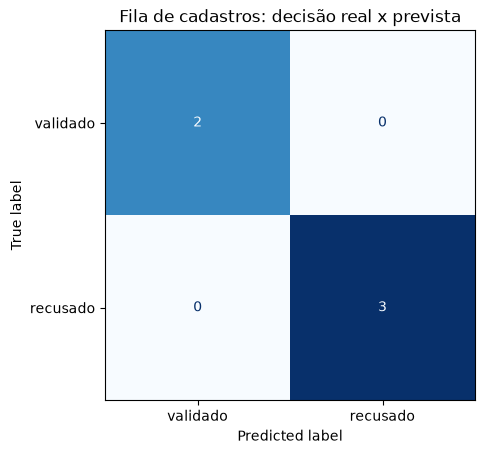

Condições que a árvore aprendeu:
|--- email_tem_nome <= 0.50
|   |--- numeros_email <= 1.00
|   |   |--- class: recusado
|   |--- numeros_email >  1.00
|   |   |--- class: recusado
|--- email_tem_nome >  0.50
|   |--- palavras_nome <= 1.50
|   |   |--- class: recusado
|   |--- palavras_nome >  1.50
|   |   |--- class: validado



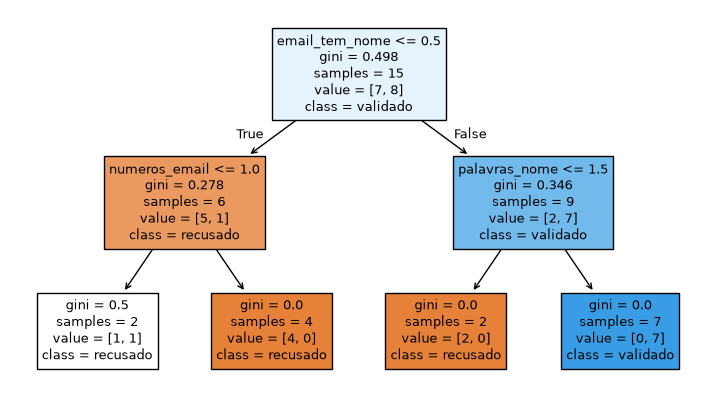

In [5]:
def treinar_e_avaliar(nome, X_treino, X_teste, y_treino, y_teste, classes, atributos):
    modelo = DecisionTreeClassifier(max_depth=2, random_state=42)
    modelo.fit(X_treino, y_treino)              # aprende só com o treino
    previsoes = modelo.predict(X_teste)          # prevê os casos de teste

    print(f"=== {nome} ===")
    print(f"Acurácia no teste: {accuracy_score(y_teste, previsoes):.1%}")
    matriz = confusion_matrix(y_teste, previsoes, labels=classes)
    print(pd.DataFrame(matriz, index=classes, columns=classes))   # linhas = real, colunas = previsto

    ConfusionMatrixDisplay(matriz, display_labels=classes).plot(cmap="Blues", colorbar=False)
    plt.title(f"{nome}: decisão real x prevista")
    plt.show()

    print("Condições que a árvore aprendeu:")
    print(export_text(modelo, feature_names=atributos))
    plt.figure(figsize=(9, 5))
    plot_tree(modelo, feature_names=atributos, class_names=list(modelo.classes_), filled=True)
    plt.show()
    return modelo, matriz

modelo_cadastro, matriz_cadastro = treinar_e_avaliar(
    "Fila de cadastros", Xc_treino, Xc_teste, yc_treino, yc_teste, ["validado", "recusado"], atrib_cadastro)

=== Fila da curadoria ===
Acurácia no teste: 83.3%
           aprovada  rejeitada
aprovada          3          0
rejeitada         1          2


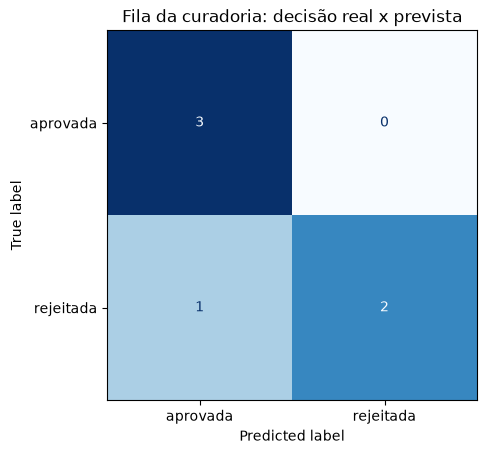

Condições que a árvore aprendeu:
|--- palavras_resumo <= 152.50
|   |--- class: rejeitada
|--- palavras_resumo >  152.50
|   |--- palavras_chave <= 2.50
|   |   |--- class: rejeitada
|   |--- palavras_chave >  2.50
|   |   |--- class: aprovada



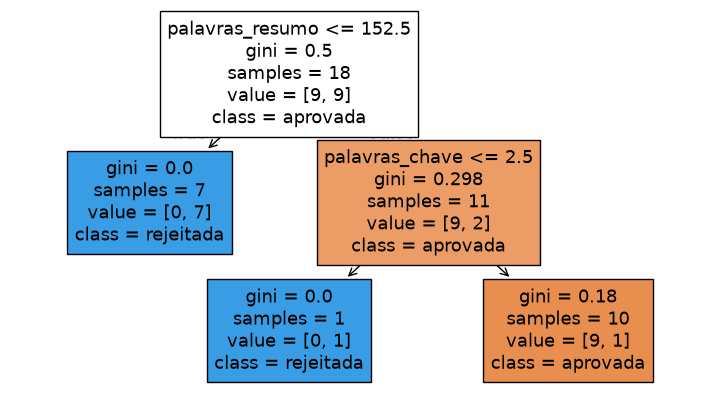

In [6]:
modelo_tcc, matriz_tcc = treinar_e_avaliar(
    "Fila da curadoria", Xt_treino, Xt_teste, yt_treino, yt_teste, ["aprovada", "rejeitada"], atrib_tcc)

In [7]:
# conferência extra: como cada modelo se sai nas exceções que colocamos de propósito
print(pd.DataFrame({
    "real": cadastros.loc[[20], "decisao"],
    "previsto": modelo_cadastro.predict(cadastros.loc[[20], atrib_cadastro]),
    "estava no": ["teste" if 20 in Xc_teste.index else "treino"],
}), "\n")
print(pd.DataFrame({
    "real": tccs.loc[[21, 24], "decisao"],
    "previsto": modelo_tcc.predict(tccs.loc[[21, 24], atrib_tcc]),
    "estava no": ["teste" if i in Xt_teste.index else "treino" for i in [21, 24]],
}))

        real  previsto estava no
20  validado  recusado    treino 

         real  previsto estava no
21  rejeitada  aprovada    treino
24  rejeitada  aprovada     teste


**O que tiramos disso:**

* **Fila de cadastros:** 100% no teste, 5 acertos em 5 (2 validados e 3 recusados na diagonal). A árvore aprendeu que e-mail sem o nome da pessoa (`email_tem_nome <= 0.5`) leva a recusado e que, com nome no e-mail, nome de uma palavra só (`palavras_nome <= 1.5`) também leva a recusado. A linha 20 (e-mail de setor) ficou no treino e mesmo assim a árvore a prevê como recusada: o caso aparece uma vez só e ela não consegue separá-lo.
* **Fila da curadoria:** 83,3% no teste, 5 acertos em 6. Os 3 aprovados foram previstos certo e 1 dos 3 rejeitados foi previsto como aprovado. A árvore aprendeu `palavras_resumo <= 152.5` → rejeitada e, com resumo maior, `palavras_chave <= 2.5` → rejeitada, praticamente os critérios que usamos para rotular. Ela não usou `tecnologias` nem `tem_abstract`. O único erro foi a linha 24, a da monografia incompleta; a linha 21 ficou no treino, mas também é prevista como aprovada.
* Nos dois casos o motivo das exceções (e-mail de setor, termo ilegível, monografia incompleta) não está nos atributos. Isso mostra o limite dos modelos: eles só enxergam o que entra em `X`. Os 100% da fila de cadastros também não dizem muito, porque são só 5 casos e os dados seguem uma regra simples criada por nós.

## 6. Base de conhecimento e motor de inferência

As previsões viram os fatos `previsao_cadastro` e `previsao_tcc`. Os outros fatos vêm das regras de negócio do squad 5; neste notebook eles são informados na consulta ou calculados, sem conexão com o banco do projeto.

**Fila de cadastros (administrador) · origem: BL-11, BL-12 e BL-20, parte da Julyane**

| Regra | SE | ENTÃO | Origem |
|---|---|---|---|
| R1 | previsão = validado E vínculo confirmado | validar e escolher pelo menos um perfil | `validar_cadastro` exige perfil (RN-26, RN-40) |
| R2 | previsão = validado E vínculo não confirmado | confirmar o vínculo com a coordenação antes de validar | escrita pelo grupo |
| R3 | previsão = recusado E vínculo confirmado | conferir nome e e-mail com a pessoa antes de decidir | escrita pelo grupo |
| R4 | previsão = recusado E vínculo não confirmado | recusar informando o motivo | recusa exige motivo (RN-36) |

**Acesso à fila da curadoria · ligação entre as duas partes**

| Regra | SE | ENTÃO | Origem |
|---|---|---|---|
| R5 | o cadastro não foi validado | `acesso_liberado = False`; aguardar a validação do administrador | RN-03 (BL-11, BL-12) |
| R6 | cadastro validado E perfil ativo não é Curadoria | `acesso_liberado = False`; trocar o perfil ou pedir ao administrador que o adicione | RN-27, RN-40 (BL-20) |
| R7 | cadastro validado E perfil Curadoria E foi a própria pessoa que enviou o TCC | `acesso_liberado = False`; deixar para outra pessoa da curadoria | RN-28 (BL-35) |
| R8 | cadastro validado E perfil Curadoria E não enviou o TCC | `acesso_liberado = True` (novo fato) | RN-03, RN-27, RN-28 |

**Fila da curadoria · origem: BL-35 e BL-36, parte do João**

| Regra | SE | ENTÃO | Origem |
|---|---|---|---|
| R9 | acesso liberado E apresentação ainda no futuro | aguardar a data para aprovar; rejeitar com motivo continua possível | RN-41 (BL-36) |
| R10 | acesso liberado E possível duplicado | comparar com o outro TCC antes de decidir | RN-44 (BL-35) |
| R11 | acesso liberado E previsão = aprovada | conferir monografia e termo antes de aprovar | escrita pelo grupo |
| R12 | acesso liberado E previsão = rejeitada | conferir resumo e palavras-chave; rejeitar com motivo se confirmar | RN-09 |

**Como o motor raciocina.** Usamos o encadeamento para frente (*forward chaining*) visto na aula de sistemas especialistas: o motor parte dos fatos conhecidos, dispara toda regra cujas condições são verdadeiras e acrescenta as conclusões como novos fatos, repetindo até nenhuma regra nova disparar. Por isso a fila da curadoria não recebe "acesso liberado" pronto: esse fato é **deduzido** pelas regras R5 a R8 a partir do resultado da fila de cadastros, e só então as regras R9 a R12 podem disparar.

Quando mais de uma regra com recomendação dispara, vale a ordem da base (a mais acima tem prioridade), como na aula 12: um bloqueio de acesso vem antes de tudo, a data de apresentação vem antes da duplicidade, e a duplicidade antes das regras que usam a previsão. O motor devolve a recomendação escolhida e a lista de todas as regras que dispararam, para explicar o raciocínio.

In [8]:
regras = [
    # ----- fila de cadastros (administrador) -----
    {"id": "R1", "fila": "cadastros", "se": {"previsao_cadastro": "validado", "vinculo_confirmado": True},
     "acao": "Validar o cadastro e escolher pelo menos um perfil (o Orientador já vem marcado)."},
    {"id": "R2", "fila": "cadastros", "se": {"previsao_cadastro": "validado", "vinculo_confirmado": False},
     "acao": "Confirmar com a coordenação se a pessoa é da faculdade antes de validar."},
    {"id": "R3", "fila": "cadastros", "se": {"previsao_cadastro": "recusado", "vinculo_confirmado": True},
     "acao": "Falar com a pessoa para conferir nome e e-mail antes de decidir."},
    {"id": "R4", "fila": "cadastros", "se": {"previsao_cadastro": "recusado", "vinculo_confirmado": False},
     "acao": "Recusar informando o motivo; o cadastro é apagado e a pessoa recebe o motivo por e-mail (RN-36)."},

    # ----- acesso à fila da curadoria (ligação entre as duas partes) -----
    {"id": "R5", "fila": "curadoria", "se": {"cadastro_validado": False},
     "entao": {"acesso_liberado": False},
     "acao": "Sem acesso à fila: o cadastro ainda não foi validado pelo administrador (RN-03)."},
    {"id": "R6", "fila": "curadoria", "se": {"cadastro_validado": True, "curadoria_ativa": False},
     "entao": {"acesso_liberado": False},
     "acao": "Trocar para o perfil Curadoria no menu do topo; se a pessoa não tiver esse perfil, "
             "o administrador precisa adicioná-lo (RN-27, RN-40)."},
    {"id": "R7", "fila": "curadoria", "se": {"cadastro_validado": True, "curadoria_ativa": True, "enviou_o_tcc": True},
     "entao": {"acesso_liberado": False},
     "acao": "Não analisar: o TCC foi enviado pela própria pessoa e fica para outra pessoa da curadoria (RN-28)."},
    {"id": "R8", "fila": "curadoria", "se": {"cadastro_validado": True, "curadoria_ativa": True, "enviou_o_tcc": False},
     "entao": {"acesso_liberado": True}},            # só deduz um fato novo, sem recomendação própria

    # ----- fila da curadoria -----
    {"id": "R9", "fila": "curadoria", "se": {"acesso_liberado": True, "apresentacao_futura": True},
     "acao": "Não aprovar ainda: a aprovação fica bloqueada até a data de apresentação (RN-41). "
             "Se houver problema, já pode rejeitar com motivo."},
    {"id": "R10", "fila": "curadoria", "se": {"acesso_liberado": True, "possivel_duplicado": True},
     "acao": "Comparar com o TCC apontado como possível duplicado antes de decidir (RN-44)."},
    {"id": "R11", "fila": "curadoria", "se": {"acesso_liberado": True, "previsao_tcc": "aprovada"},
     "acao": "Seguir com a análise completa: conferir a monografia e o termo de autorização antes de aprovar."},
    {"id": "R12", "fila": "curadoria", "se": {"acesso_liberado": True, "previsao_tcc": "rejeitada"},
     "acao": "Conferir resumo e palavras-chave; se estiverem incompletos, rejeitar informando o motivo (RN-09)."},
]

def inferir(fila, fatos):
    """Motor de inferência com encadeamento para frente.
    Dispara toda regra da fila cujas condições batem, acrescenta as conclusões como novos fatos
    e repete até nenhuma regra nova disparar. A recomendação é a da regra disparada mais acima na base."""
    fatos = dict(fatos)
    disparadas = []
    mudou = True
    while mudou:
        mudou = False
        for regra in regras:
            if regra["fila"] != fila or regra["id"] in disparadas:
                continue
            if all(fatos.get(nome) == valor for nome, valor in regra["se"].items()):
                disparadas.append(regra["id"])
                fatos.update(regra.get("entao", {}))     # novo fato deduzido
                mudou = True

    com_acao = [r for r in regras if r["id"] in disparadas and "acao" in r]
    if not com_acao:
        raise ValueError("Nenhuma regra compatível com os fatos.")
    escolhida = com_acao[0]
    deduzidos = {k: v for r in regras if r["id"] in disparadas for k, v in r.get("entao", {}).items()}
    return {
        "regras_disparadas": " -> ".join(disparadas),
        "fatos_deduzidos": deduzidos or "nenhum",
        "regra": escolhida["id"],
        "recomendacao": escolhida["acao"],
        "explicacao": "fatos usados: " + ", ".join(f"{n}={fatos[n]}" for n in escolhida["se"]),
    }

## 7. Integrar os modelos ao sistema especialista
Cada fila tem uma função que confere as entradas, pede a previsão ao modelo, monta os fatos e chama o motor. Como no exemplo da professora, as duas avisam quando a entrada sai do intervalo que o modelo viu no treino.

Na fila de cadastros também calculamos quantos dias faltam para o cadastro ser apagado automaticamente, com o mesmo prazo de 30 dias do squad 5 (RN-36).

In [9]:
DIAS_PARA_VALIDAR = 30   # o mesmo prazo do squad 5 (RN-36)

def fora_do_treino(novo, X_treino, atributos):
    return any(not X_treino[c].min() <= novo[c].iloc[0] <= X_treino[c].max() for c in atributos)

def analisar_cadastro(palavras_nome, email_tem_nome, numeros_email, dias_na_fila, vinculo_confirmado):
    """Fila de cadastros: o que o administrador deve fazer com um cadastro não validado."""
    if palavras_nome < 1 or numeros_email < 0 or email_tem_nome not in (0, 1):
        raise ValueError("Confira os dados do cadastro.")
    if not isinstance(vinculo_confirmado, bool):
        raise ValueError("vinculo_confirmado deve ser True ou False.")

    novo = pd.DataFrame([{"palavras_nome": palavras_nome, "email_tem_nome": email_tem_nome,
                          "numeros_email": numeros_email}])
    fatos = {"previsao_cadastro": modelo_cadastro.predict(novo)[0],   # fato que vem do modelo
             "vinculo_confirmado": vinculo_confirmado}                  # fato informado pelo administrador
    resultado = {"previsao_do_modelo": fatos["previsao_cadastro"], **inferir("cadastros", fatos)}

    restantes = DIAS_PARA_VALIDAR - dias_na_fila
    resultado["prazo"] = (f"Atenção: faltam {restantes} dia(s) para o cadastro ser apagado automaticamente."
                          if restantes <= 5 else f"Faltam {restantes} dias para o prazo de 30 dias.")
    resultado["aviso"] = ("Entrada fora dos intervalos observados no treino; exige revisão do administrador."
                          if fora_do_treino(novo, Xc_treino, atrib_cadastro)
                          else "Recomendação de apoio; a decisão é do administrador (RF13).")
    return resultado

def orientar_curadoria(usuario, palavras_resumo, palavras_chave, tecnologias, tem_abstract,
                       data_apresentacao, possivel_duplicado, hoje=None):
    """Fila da curadoria: o que a pessoa deve fazer com um TCC pendente.
    `usuario` traz o resultado da fila de cadastros: validado, perfil ativo e se enviou o TCC."""
    if palavras_resumo <= 0:
        raise ValueError("O resumo é obrigatório.")
    if palavras_chave < 1 or tecnologias < 1:
        raise ValueError("Informe pelo menos uma palavra-chave e uma tecnologia.")
    if tem_abstract not in (0, 1) or not isinstance(possivel_duplicado, bool):
        raise ValueError("tem_abstract deve ser 0 ou 1 e possivel_duplicado deve ser True ou False.")

    hoje = hoje or date.today()
    novo = pd.DataFrame([{"palavras_resumo": palavras_resumo, "palavras_chave": palavras_chave,
                          "tecnologias": tecnologias, "tem_abstract": tem_abstract}])
    fatos = {
        "cadastro_validado": usuario["cadastro_validado"],                  # RN-03 (fila de cadastros)
        "curadoria_ativa": usuario["perfil_ativo"] == "curadoria",           # RN-27 (perfis)
        "enviou_o_tcc": usuario["enviou_o_tcc"],                             # RN-28
        "previsao_tcc": modelo_tcc.predict(novo)[0],                         # fato que vem do modelo
        "apresentacao_futura": data_apresentacao > hoje,                     # RN-41
        "possivel_duplicado": possivel_duplicado,                            # RN-44
    }
    resultado = {"previsao_do_modelo": fatos["previsao_tcc"], **inferir("curadoria", fatos)}
    resultado["aviso"] = ("Entrada fora dos intervalos observados no treino; exige revisão da curadoria."
                          if fora_do_treino(novo, Xt_treino, atrib_tcc)
                          else "Recomendação de apoio; a decisão é da curadoria (RN-07).")
    return resultado

## 8. Três casos novos
Nenhum dos dados abaixo está nos datasets. Cada caso acompanha uma pessoa da curadoria desde o cadastro até a primeira análise de TCC, passando pelas duas filas. Fixamos `hoje = 16/11/2026` para o resultado não mudar conforme o dia em que o notebook rodar.

Para ligar as duas filas, consideramos que o administrador seguiu a recomendação: o cadastro só conta como validado quando a regra aplicada foi a R1, e nesse caso ele atribuiu o perfil Curadoria.

In [10]:
HOJE = date(2026, 11, 16)

casos = [
    {   # caso 1: cadastro normal e vínculo confirmado; depois analisa um TCC com metadados bons
        "cadastro": (3, 1, 0, 4, True),                       # nome, e-mail tem nome, números, dias na fila, vínculo
        "perfil_ativo": "curadoria", "enviou_o_tcc": False,
        "tcc": (240, 4, 2, 1, date(2026, 11, 5), False),      # resumo, chaves, tecnologias, abstract, data, duplicado
    },
    {   # caso 2: cadastro normal, mas o vínculo ainda não foi confirmado; tenta abrir a fila mesmo assim
        "cadastro": (4, 1, 1, 12, False),
        "perfil_ativo": None, "enviou_o_tcc": False,
        "tcc": (90, 2, 1, 0, date(2026, 10, 28), False),
    },
    {   # caso 3: cadastro validado como Curadoria; o TCC tem apresentação marcada para dezembro
        "cadastro": (2, 1, 0, 1, True),
        "perfil_ativo": "curadoria", "enviou_o_tcc": False,
        "tcc": (300, 5, 3, 1, date(2026, 12, 3), False),
    },
]

resultados = []
for i, caso in enumerate(casos, 1):
    print(f"\n==================== CASO {i} ====================")
    print("Fila de cadastros:", caso["cadastro"])
    r_cad = analisar_cadastro(*caso["cadastro"])
    for campo, valor in r_cad.items():
        print(f"  {campo}: {valor}")

    usuario = {"cadastro_validado": r_cad["regra"] == "R1",
               "perfil_ativo": caso["perfil_ativo"] if r_cad["regra"] == "R1" else None,
               "enviou_o_tcc": caso["enviou_o_tcc"]}
    t = caso["tcc"]
    print(f"Fila da curadoria: {t[0]} palavras no resumo; {t[1]} palavras-chave; {t[2]} tecnologias; "
          f"abstract={t[3]}; apresentação {t[4]:%d/%m/%Y}; duplicado={t[5]}")
    r_tcc = orientar_curadoria(usuario, *t, hoje=HOJE)
    for campo, valor in r_tcc.items():
        print(f"  {campo}: {valor}")
    resultados.append((r_cad["regra"], r_tcc["regra"]))


==================== CASO 1 ====================
Fila de cadastros: (3, 1, 0, 4, True)
  previsao_do_modelo: validado
  regras_disparadas: R1
  fatos_deduzidos: nenhum
  regra: R1
  recomendacao: Validar o cadastro e escolher pelo menos um perfil (o Orientador já vem marcado).
  explicacao: fatos usados: previsao_cadastro=validado, vinculo_confirmado=True
  prazo: Faltam 26 dias para o prazo de 30 dias.
  aviso: Recomendação de apoio; a decisão é do administrador (RF13).
Fila da curadoria: 240 palavras no resumo; 4 palavras-chave; 2 tecnologias; abstract=1; apresentação 05/11/2026; duplicado=False
  previsao_do_modelo: aprovada
  regras_disparadas: R8 -> R11
  fatos_deduzidos: {'acesso_liberado': True}
  regra: R11
  recomendacao: Seguir com a análise completa: conferir a monografia e o termo de autorização antes de aprovar.
  explicacao: fatos usados: acesso_liberado=True, previsao_tcc=aprovada
  aviso: Recomendação de apoio; a decisão é da curadoria (RN-07).

==================== CA

**Análise dos três casos:**

* **Caso 1:** nome com 3 palavras e e-mail com o nome da pessoa, então o modelo da fila de cadastros prevê `validado`; como o vínculo já foi confirmado, dispara a **R1** e o administrador valida com o perfil Curadoria. Na fila da curadoria o motor encadeia: a **R8** deduz o fato novo `acesso_liberado = True` e, com ele, dispara a **R11**. A pessoa abre um TCC com 240 palavras no resumo e 4 palavras-chave, o modelo prevê `aprovada`, a apresentação já passou e não há duplicado, então a recomendação é seguir com a análise completa, conferindo monografia e termo.
* **Caso 2:** o modelo prevê `validado`, mas o vínculo não foi confirmado, então dispara a **R2** e o administrador ainda precisa confirmar com a coordenação. Enquanto isso o cadastro continua não validado, e quando a pessoa tenta abrir a fila da curadoria dispara a **R5**, que deduz `acesso_liberado = False` (RN-03). O modelo prevê `rejeitada` para o TCC, mas a R12 não dispara, porque sem acesso liberado nenhuma regra da fila da curadoria é ativada.
* **Caso 3:** cadastro validado pela **R1** e perfil Curadoria ativo. A R8 libera o acesso e, a partir daí, disparam duas regras: a **R9** (apresentação em 03/12/2026) e a R11 (previsão `aprovada`). Pela ordem da base, a R9 tem prioridade: mesmo com metadados bons, o sistema não deixa aprovar antes da data, igual ao que o squad 5 faz em `aprovar_tcc`. A lista `regras_disparadas` mostra as duas, o que ajuda a explicar a decisão.

Nos três casos aparece o aviso "Recomendação de apoio": todas as entradas estão dentro dos intervalos vistos no treino.

## 9. Comparação: mudar só um fato
Pegamos o TCC do caso 1 e mudamos um fato de cada vez. Os números do TCC são sempre os mesmos, então a previsão do modelo não muda; quem muda a recomendação é o sistema especialista.

In [11]:
tcc_caso1 = (240, 4, 2, 1, date(2026, 11, 5))
base = {"cadastro_validado": True, "perfil_ativo": "curadoria", "enviou_o_tcc": False}

variacoes = [
    ("original (caso 1)",                 base, False),
    ("perfil ativo = orientador",         {**base, "perfil_ativo": "orientador"}, False),
    ("a própria pessoa enviou o TCC",     {**base, "enviou_o_tcc": True}, False),
    ("possível duplicado",                base, True),
]
for nome, usuario, duplicado in variacoes:
    r = orientar_curadoria(usuario, *tcc_caso1, duplicado, hoje=HOJE)
    print(f"{nome:32} -> previsão: {r['previsao_do_modelo']} | disparadas: {r['regras_disparadas']}")
    print(f"{'':32}    {r['regra']}: {r['recomendacao']}")

original (caso 1)                -> previsão: aprovada | disparadas: R8 -> R11
                                    R11: Seguir com a análise completa: conferir a monografia e o termo de autorização antes de aprovar.
perfil ativo = orientador        -> previsão: aprovada | disparadas: R6
                                    R6: Trocar para o perfil Curadoria no menu do topo; se a pessoa não tiver esse perfil, o administrador precisa adicioná-lo (RN-27, RN-40).
a própria pessoa enviou o TCC    -> previsão: aprovada | disparadas: R7
                                    R7: Não analisar: o TCC foi enviado pela própria pessoa e fica para outra pessoa da curadoria (RN-28).
possível duplicado               -> previsão: aprovada | disparadas: R8 -> R10 -> R11
                                    R10: Comparar com o TCC apontado como possível duplicado antes de decidir (RN-44).


A previsão continuou `aprovada` nas quatro linhas. A recomendação mudou de R11 para R6, R7 ou R10 só por causa de fatos que não passam pelo modelo:

* com o perfil Orientador ativo, a pessoa tem o cadastro validado mas não pode analisar (R6). É a regra de perfis do BL-20: basta trocar o perfil no menu, ou o administrador adicionar a Curadoria;
* se foi a própria pessoa que enviou o TCC, ele fica para outra pessoa da curadoria (R7, RN-28);
* com possível duplicado, a curadoria compara antes de decidir (R10, RN-44). Aqui a R11 também dispara, mas a R10 vem antes na base.

Isso responde à pergunta da aula sobre o fato que não aparece entre os atributos: assim como a "dificuldade em lógica" no exemplo do orientador de estudos, perfil, autoria e duplicidade são informados ou calculados pelo sistema e entram direto nas regras, sem passar pelo modelo.

## 10. Erros, limitações e cuidados

* **Dados simulados e poucos:** são 20 cadastros (5 no teste) e 24 TCCs (6 no teste). Na fila da curadoria, um acerto a mais ou a menos muda a acurácia em quase 17 pontos; na de cadastros, em 20. Não dá para dizer que os modelos funcionam em uso real, e não ajustamos os modelos para melhorar esse resultado.
* **Os rótulos vêm de critérios nossos:** como nós mesmos rotulamos, as árvores só reaprendem esses critérios. Com decisões reais do administrador e da curadoria, o padrão poderia ser outro.
* **Os modelos só veem o que está em `X`:** e-mail de setor (linha 20 dos cadastros), termo ilegível e monografia incompleta (linhas 21 e 24 dos TCCs) não são capturados pelos atributos. Por isso a R11 manda conferir monografia e termo mesmo quando a previsão é `aprovada`, e a R2 e a R3 pedem confirmação humana antes de validar ou recusar um cadastro.
* **Viés na fila de cadastros:** pessoas com nome curto de verdade, nome estrangeiro ou e-mail sem o nome podem ser previstas como `recusado`. É o risco mais sério do sistema, porque uma recusa apaga o cadastro. Por isso a decisão continua com o administrador e a R3 manda falar com a pessoa antes de recusar quando o vínculo já foi confirmado.
* **Exemplos pouco representados:** não há TCC com resumo acima de 400 palavras, nem em inglês ou espanhol (o campo `idioma` existe no squad 5), nem separação por curso. O aviso de "fora do intervalo" confere apenas os atributos numéricos e não detecta diferenças de idioma, curso ou conteúdo.
* **Dados pessoais (LGPD):** não usamos nome, e-mail, título nem data de nascimento, só contagens. Uma aplicação com dados reais exigiria avaliar a finalidade, as permissões de acesso, a minimização e o risco de reidentificação. O squad 5 já apaga cadastros parados há 30 dias para não guardar dados sem finalidade.
* **Supervisão humana:** só o administrador valida ou recusa cadastros (RF13) e só a curadoria aprova ou rejeita TCCs (RN-07). Este protótipo sugere o que fazer e explica qual regra disparou; não altera nenhuma fila do sistema real.

**Questões de fechamento da aula:**

* *Qual parte aprende com os dados?* As duas árvores de decisão, que aprenderam limites para o nome e o e-mail no cadastro e para o resumo e as palavras-chave no TCC.
* *Qual parte aplica as regras humanas do negócio?* A base de conhecimento (regras R1 a R12) e o motor `inferir`, que encadeia as regras para frente e deduz fatos novos, como o `acesso_liberado`. A maioria das regras vem direto das regras de negócio do squad 5.
* *O que acontece ao mudar apenas um fato que não é atributo?* A previsão continua igual e a recomendação muda, como mostrado na seção 9.
* *Um resultado de 100% em poucos casos é suficiente para uso real?* Não. A fila de cadastros deu 100% em 5 casos e a da curadoria 83,3% em 6. Outra divisão dos dados poderia produzir acurácias diferentes sem que os modelos ficassem melhores.

## Referências
* IBM. Guia de Aprendizado de Máquina: https://www.ibm.com/br-pt/think/machine-learning
* IBM. Aprendizado supervisionado: https://www.ibm.com/br-pt/think/topics/supervised-learning
* scikit-learn. [DecisionTreeClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html) e [train_test_split](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html) (documentação oficial)
* Notebook e apresentação da aula 13: Aprendizado de Máquina – Introdução (Profa. Kadidja Valéria)
* Documentos do squad 5: `docs/requirements.md` (RN-03, RN-06, RN-07, RN-09, RN-25, RN-26, RN-27, RN-28, RN-29, RN-36, RN-40, RN-41, RN-44), `contas/services.py`, `curadoria/services.py` e `tccs/services.py`